# Text Generator Model

This notebook documents training a transformer language model from scratch on Jane Austen's *Pride and Prejudice*. It covers loading the text, training a tokenizer, building and training the model, and generating text with different prompts and temperatures. It ends with conclusions and a discussion of why training a transformer from scratch is slow and demanding.

The model is built with `Keras`, using `TensorFlow` as its backend, and the tokenizer comes from the `sentencepiece` library. `numpy` is used to build the training sequences and `matplotlib` to plot the training curves. A random seed is set with `keras.utils.set_random_seed(42)` so that runs can be repeated and compared.

In [1]:
# Cell 1: Setup and imports
import os
os.environ['KERAS_BACKEND'] = 'tensorflow'
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # stops unnecesary logs when training using ubuntu

import numpy as np
import keras
import sentencepiece as spm

keras.utils.set_random_seed(42)

print(f"Keras version: {keras.__version__}")
print(f"Keras backend: {keras.config.backend()}")

I0000 00:00:1795094949.164480  612086 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795094950.951740  612086 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Keras version: 3.15.1
Keras backend: tensorflow


## Dataset

We chose *Pride and Prejudice* by Jane Austen, and downloaded it from Project Gutenberg where it is downloadable copyright free. A separate script cleaned it by removing the header and footer, the styling characters (`_`), the chapter titles and extra whitespaces. The result was saved as `jane_austen_pride_and_prejudice_clean.txt`, which is loaded here.

The original file was 757 KB and the cleaned file is 693 KB, which is 684047 characters, which is above the required 100 KB. The whole cleaned text is stored in the `text` variable.

In [2]:
# Cell 2: Load and prepare text data
with open('./datasets/jane_austen_pride_and_prejudice_clean.txt', 'r', encoding='utf-8-sig') as file:
    text = file.read()

print(f"Text length: {len(text)} characters")
print(f"First 200 characters: {text[:200]}")

Text length: 684047 characters
First 200 characters: It is a truth universally acknowledged, that a single man in possession of a good fortune must be in want of a wife.

However little known the feelings or views of such a man may be on his first enter


## Train SentencePiece model

The model cannot read plain text, so the text is first split into tokens, which are words or parts of words. A SentencePiece tokenizer is trained on the book for this. It uses byte pair encoding (BPE), which starts from single letters and joins the most common pairs into longer pieces.

`vocab_size` is the number of different tokens, here 10000. If it is too small, words are split into many small pieces, and the model may join them into words that do not exist. If it is too large, rare words appear only a few times in the book, so the model cannot learn them well.

The trained tokenizer is saved as `pride_and_prejudice_sp.model`. After training, the tokenizer is tested on a sentence from the book. Every word became one token, and each punctuation mark became its own token. The `_` symbol means that the token starts with a space.

In [3]:
# Cell 3: Train SentencePiece model
# Save text to a temporary file for SentencePiece training
temp_file = 'pride_and_prejudice_temp.txt'
with open(temp_file, 'w', encoding='utf-8') as f:
    f.write(text)

# Train SentencePiece model
vocab_size = 10000 
model_prefix = 'pride_and_prejudice_sp'

spm.SentencePieceTrainer.train(
    input=temp_file,
    model_prefix=model_prefix,
    vocab_size=vocab_size,
    character_coverage=1.0,  # 1.0 for English and most other European languagaes (usually)
    model_type='bpe',
    user_defined_symbols=['<PAD>', '<UNK>']
)

# Load the trained tokenizer
sp = spm.SentencePieceProcessor()
sp.load(f"{model_prefix}.model")

# Test tokenization
test_text = "Elizabeth, when Mr. Darcy gave her the letter, did not expect it to contain a renewal of his offers, she had formed no expectation at all of its contents."
tokens = sp.encode_as_pieces(test_text)
print(f"Tokenized example: {tokens}")
print(f"Vocabulary size: {sp.get_piece_size()}")

Tokenized example: ['▁Elizabeth', ',', '▁when', '▁Mr', '.', '▁Darcy', '▁gave', '▁her', '▁the', '▁letter', ',', '▁did', '▁not', '▁expect', '▁it', '▁to', '▁contain', '▁a', '▁renewal', '▁of', '▁his', '▁offers', ',', '▁she', '▁had', '▁formed', '▁no', '▁expectation', '▁at', '▁all', '▁of', '▁its', '▁contents', '.']
Vocabulary size: 10000


I0000 00:00:1795094951.670733  612086 sentencepiece_trainer.cc:149] Starts training with : 
trainer_spec {
  input: pride_and_prejudice_temp.txt
  input_format: 
  model_prefix: pride_and_prejudice_sp
  model_type: BPE
  vocab_size: 10000
  character_coverage: 1
  input_sentence_size: 0
  shuffle_input_sentence: 1
  seed_sentencepiece_size: 1000000
  shrinking_factor: 0.75
  max_sentence_length: 4192
  num_threads: 16
  num_sub_iterations: 2
  max_sentencepiece_length: 16
  split_by_unicode_script: 1
  split_by_number: 1
  split_by_whitespace: 1
  split_digits: 0
  pretokenization_delimiter: 
  treat_whitespace_as_suffix: 0
  allow_whitespace_only_pieces: 0
  user_defined_symbols: <PAD>
  user_defined_symbols: <UNK>
  required_chars: 
  byte_fallback: 0
  auto_character_coverage: 0
  vocabulary_output_piece_score: 1
  seed_sentencepieces_file: 
  hard_vocab_limit: 1
  use_all_vocab: 0
  unk_id: 0
  bos_id: 1
  eos_id: 2
  pad_id: -1
  unk_piece: <unk>
  bos_piece: <s>
  eos_piece: </s>

## Prepare training data

The whole text is first converted into token ids with the trained tokenizer, which gives 145227 tokens. `seq_length` is the number of tokens the model sees at once, which is its context window, here 128 tokens. There are 145099 sequences, and both the input and target arrays have the shape `(145099, 128)`.

The sequences are split into training and validation data, each with its own inputs and targets.

In [4]:
# Cell 4: Prepare training data
# Tokenize the text
seq_length = 128 
pieces = sp.encode_as_ids(text)
print(f"Total tokens: {len(pieces)}")

# Create sequences
sequences = []
for i in range(0, len(pieces) - seq_length):
    # Input: first seq_length tokens, Target: next seq_length tokens (shifted by 1)
    sequences.append(pieces[i:i+seq_length+1])

# Convert to NumPy arrays
sequences = np.array(sequences)
inputs = sequences[:, :-1]  # All tokens except the last one
targets = sequences[:, 1:]  # All tokens except the first one

print(f"Number of sequences: {len(sequences)}")
print(f"Input shape: {inputs.shape}")
print(f"Target shape: {targets.shape}")

# Split into training and validation sets: the first 90 % of the text for training,
# the rest for validation. Neighbouring windows share 63 of their 64 tokens, so a
# random split would put almost the same windows in both sets. Skipping seq_length
# windows at the split point leaves no shared tokens between the sets.
split = int(0.9 * len(sequences))
train_inputs, train_targets = inputs[:split], targets[:split]
val_inputs, val_targets = inputs[split + seq_length:], targets[split + seq_length:]

Total tokens: 145227
Number of sequences: 145099
Input shape: (145099, 128)
Target shape: (145099, 128)


## Define the model

The model is a small transformer with four main settings: `embed_dim = 200`, `num_heads = 5`, `ff_dim = 400` and `num_layers = 3`. Each token is turned into a vector of 200 numbers, and positional encoding is added so the model knows the word order. The data then passes through three transformer blocks. In each block, attention lets every token look at the tokens before it, but not at the ones after it. The attention is split into five heads, so the model can learn different patterns in the text. A feed-forward network with 400 units then processes each token further. A dropout of 0.1 helps prevent the model from memorising the training data. Finally, the model gives each possible next token a score and predicts the one with the highest score.

In [5]:
# Cell 5: Define the model
def get_positional_encoding(max_len, d_model):
    """Create sinusoidal positional encoding."""
    positions = np.arange(max_len)[:, np.newaxis]
    angles = np.arange(d_model)[np.newaxis, :] / d_model
    angles = 1 / (10000**angles)

    pos_encoding = positions * angles
    pos_encoding[:, 0::2] = np.sin(pos_encoding[:, 0::2])
    pos_encoding[:, 1::2] = np.cos(pos_encoding[:, 1::2])

    return pos_encoding

# Define model parameters
embed_dim = 200
num_heads = 5
ff_dim = 400
num_layers = 3

# Create the model
inputs = keras.Input(shape=(seq_length,))
embedding_layer = keras.layers.Embedding(sp.get_piece_size(), embed_dim)(inputs)

# Add positional encoding
pos_encoding = get_positional_encoding(seq_length, embed_dim)
x = embedding_layer + pos_encoding

# Transformer blocks
for _ in range(num_layers):
    # Multi-head attention with causal mask
    attention_output = keras.layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=embed_dim // num_heads,
        dropout=0.1
    )(x, x, use_causal_mask=True)

    # Add & Norm
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + attention_output)

    # Feed-forward network
    ffn = keras.Sequential([
        keras.layers.Dense(ff_dim, activation="relu"),
        keras.layers.Dense(embed_dim),
        keras.layers.Dropout(0.1)
    ])
    ffn_output = ffn(x)

    # Add & Norm
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + ffn_output)

# Final output layer
outputs = keras.layers.Dense(sp.get_piece_size())(x)

# Create model
model = keras.Model(inputs=inputs, outputs=outputs)

# Compile model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 128, 200)  │  2,000,000 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 128, 200)  │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 128, 200)  │    160,800 │ add[0][0],        │
│ (MultiHeadAttentio… │                   │            │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 128, 200)  │          0 │ add[0][0],        │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 128, 200)  │        400 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 128, 200)  │    160,600 │ layer_normalizat… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 128, 200)  │          0 │ layer_normalizat… │
│                     │                   │            │ sequential[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 128, 200)  │        400 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 128, 200)  │    160,800 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 128, 200)  │          0 │ layer_normalizat… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 128, 200)  │        400 │ add_3[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_1        │ (None, 128, 200)  │    160,600 │ layer_normalizat… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 128, 200)  │          0 │ layer_normalizat… │
│                     │                   │            │ sequential_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 128, 200)  │        400 │ add_4[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 128, 200)  │    160,800 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_5 (Add)         │ (None, 128, 200)  │          0 │ layer_normalizat… │
│                     │                   │            │ multi_head_atten

 Total params: 4,976,600 (18.98 MB)

 Trainable params: 4,976,600 (18.98 MB)

 Non-trainable params: 0 (0.00 B)

The model is compiled with the Adam optimizer and a learning rate of 3e-4. The model has 4,976,600 parameters, all of which are trainable.

## Train the model

The model is trained with a `batch_size` of 128 for at most 100 epochs. `EarlyStopping` stops the training when the validation loss has not improved for 3 epochs and goes back to the best weights. `ReduceLROnPlateau` halves the learning rate when the validation loss stops improving, and `ModelCheckpoint` saves the best model to a file.

With the current parameters, the best epoch was the first one, and training stopped after epoch 4. After the first epoch, the validation loss only grew, and the validation accuracy fell. This shows clear overfitting.

In [6]:
# Cell 6: Train the model
batch_size = 128
epochs = 100

history = model.fit(
    train_inputs, train_targets,
    validation_data=(val_inputs, val_targets),
    batch_size=batch_size,
    epochs=epochs,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=1),
        keras.callbacks.ModelCheckpoint('pride_and_prejudice_best_model.keras', save_best_only=True)
    ]
)

Epoch 1/100
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 73s 47ms/step - accuracy: 0.1714 - loss: 4.9404 - val_accuracy: 0.1806 - val_loss: 4.8579 - learning_rate: 3.0000e-04
Epoch 2/100
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 26s 25ms/step - accuracy: 0.3311 - loss: 3.1874 - val_accuracy: 0.1656 - val_loss: 5.5393 - learning_rate: 3.0000e-04
Epoch 3/100
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 26s 25ms/step - accuracy: 0.5093 - loss: 2.1017 - val_accuracy: 0.1547 - val_loss: 6.2031 - learning_rate: 1.5000e-04
Epoch 4/100
1021/1021 ━━━━━━━━━━━━━━━━━━━━ 26s 25ms/step - accuracy: 0.6051 - loss: 1.6384 - val_accuracy: 0.1481 - val_loss: 6.5963 - learning_rate: 7.5000e-05
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 1.


## Plot training metrics

The graphs display the training and validation loss and accuracy for each epoch. The curves show how the model learns and helps to identify whether the model is overfitting.

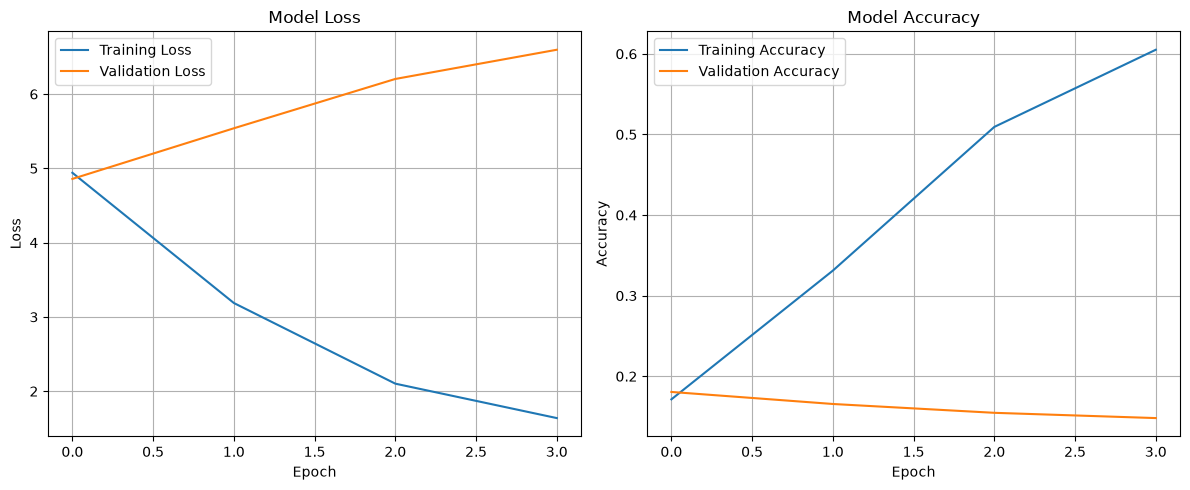

In [7]:
# Cell 7: Plot training metrics
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid()
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.grid()
plt.legend()

plt.tight_layout()
plt.show()

As seen in the first graph, the training loss declines while the validation loss increases. The validation accuracy doesn't improve either even though the training accuracy increases from 17% to 60%. Indicating, that the model is overfitting from the start.

As a result of earlystopping, the model stops after the third epoch and restores the weights of the first epoch. The best version is then saved for later use.

In [8]:
# Cell 8: Save the model
model.save('pride_and_prejudice_model.keras')
print("Model saved as 'pride_and_prejudice.keras'")

Model saved as 'pride_and_prejudice.keras'


## Generate sample text

The perforance of the model is presented with a custom function that takes a promt as an input and generates a sample text based on it. The length is specified by the parameter num_tokens. 

The randomness of the text is controlled with temparture. The scores (logits) are divided by the value of the temparture before they are converted into propabilities. With higher tempature, the generated text could be described as chaoting or creative. In which case, the temparture rises the scores of the tokens with otherwise smaller probability to be predicted.
On the contrary, with lower temparture values, the generated text might seem repetitive or even boring. The differences between the scores become much larger when the tokens with higher probabilities are emphasised.

In [9]:
def generate_text(model, sp, prompt, num_tokens=100, temperature=1.0):

    # Encode the prompt
    input_ids = sp.encode_as_ids(prompt)

    if len(input_ids) < seq_length:
        padding_length = seq_length - len(input_ids)
        input_ids = [0] * padding_length + input_ids
    else:
        padding_length = 0
        input_ids = input_ids[-seq_length:]

    # Generated tokens
    generated_ids = list(input_ids[padding_length:])

    # Generate text token by token
    for _ in range(num_tokens):
        x = np.array([input_ids])
        predictions = model.predict(x, verbose=0)[0]
        logits = predictions[-1]
        logits = logits / temperature
        exp_logits = np.exp(logits - np.max(logits))
        probs = exp_logits / np.sum(exp_logits)
        next_token = np.random.choice(len(probs), p=probs)
        generated_ids.append(next_token)
        input_ids = input_ids[1:] + [next_token]

    # Decode the generated sequence
    generated_text = sp.decode(generated_ids)

    return generated_text

The sample text is generated from the following promts. Different temparture values were tested and documented below.

In [10]:
# Cell 10: Generate sample text
prompts = [
    "Elizabeth",
    "Mr. Darcy",
    "The general prejudice",
    "A letter arrived"
]

for prompt in prompts:
    print(f"\nPrompt: {prompt}")
    generated = generate_text(model, sp, prompt, num_tokens=100, temperature=0.8) 
    print(generated)


Prompt: Elizabeth
Elizabeth. That they were to be a wide distance. “I hope I have been at any love.” “Oh, you are married.” “When I know you not, sir. I have heard you in my sister’s marrying me, you.” It is, indeed, therefore, and to be too much surprised so much as to town for. And that a book, which they is not to Brighton. The little as I shall know, you.” “I am glad of which I have not

Prompt: Mr. Darcy
Mr. Darcy and Bingley, and Maria were not long.” “But I ask off?” “I have happened to get round to be so much dreadful. I am sure I have been prudence enough to wish to overhear conclusion.” “My dear that you are to be fit to be ill? Mr. Bingley is too much more than as to ask for the other, that the power of your own excuse--a dear friend.” Darcy’s marrying visit, and she was fast estate into the same attention. He asked

Prompt: The general prejudice
The general prejudice, and was distressed. “Oh, the visit would have never be beyond the world, my fair cousins, and we were to p

The text resembles Jane Austen's writing style and some of the senteces in the text samples sound sensible. The romantic themes of love and marriage could be identified from the text as well as the characters from the original novel. 

Nevertheless, the writing is mostly nonsensical and illogical. The samples have fragmented structure and lack consistency. 

With smaller temperature values, the text became very repetitive. A sample with `temperature=0.3` said the words "I am sure" over and over again: *A letter arrived. “Oh, and I am sure, I am sure, I am not to be in the better. I am sure I am sure, I am sure I am sure I am sure I am sure I am sure, I am sure I am afraid of your opinion of my dear, and I am sure, I am sure I am sure I am sure, I am sure I am sure I am sure I am afraid of your own, I am afraid of it, and I am sure,*. That phrase is probably commonly repetited through the book.


With temparture value of 1.2, the number of incomplete tokens and broken words appear. The model tries to be creative but fails: *The general prejudice that he? And spend Meryton,, that he can I not expect Wickham, as nothing and the higher matters grew to err. If said overspread them while. Not as seemed her again indulged, undoubtedly just best,--p eccentric, Lord! For a thing, since she suited to Meryton, however, that he consider from her visitors felt without ordinary civility to discover by going large. Rec bonnet, as he most charming, such tea There was a proper manner gentleman; till last manner, gate in comparison*

The final temperature was set to 0.8. The sample texts had the best balance between common and uncommon words. The sentanced maked most sense out of the different tests.

## Conclusions

The model learned to generate a text that sounds like Pride and Prejudice on the surface-level. It can identify the character names and vocabulary of Jane Austins but lacks a clear subject. 

The model seems to understand the dialogue structure. It uses quotation marks correctly and narrates the name of the speaker: *“Oh, madam,” cried Elizabeth, “that they are a very once.”*.
The example also demonstrates that it learned to use commas and perioids grammar-wise. 

The sentences lack meaning and coherent structure. The model was trained with very little data and it limited the ability learn properly. The book has about 145 000 tokens while the model has almost 5 million parameters. The amount of parameters is much grater than the amount of the training tokens, and as a result, the model starts to overfit. The training accuracy rose from 17% to 60% but the validation accuracy didn't improve after the first epoch. The weights of the first epoch were restored as a result of EarlyStopping. 
The model can't generalise from the training text but seem to memorise the text instead. With more data, the model could generalise the training data better.

The vocab_size and temperature affected the text quality most. With balanced temperature values, a higher vocab_size improved the models sentence structure but the accuracy declined. A large vocabulary adds many parameters to the embedding and output layers, so many tokens appear only a few times and therefore couldn't be learned well. The transformer doesn't have any prior knowledge of a language and everything is learned from the training data alone. A smaller vocabulary suited the small dataset better and improved learning accuracy but grew the amount of made-up words that appeared in the samples. This could be adjusted with the temperature.

Additionally, different values and combinations of parameters vocab_size, seq_length, embed_dim, num_heads, ff_dim and num_layers were tested. A few example architechtures are listed below to demostrate the affects of the parameter changes:

**Original values**
```python
vocab_size = 10000
seq_length = 64 
embed_dim = 192
num_heads = 4
ff_dim = 384
num_layers = 2 
```

**Large model**
```python
vocab_size = 12000
seq_length = 32
embed_dim = 454
num_heads = 12
ff_dim = 908
num_layers = 7 
```

**Small model**
```python
vocab_size = 6000
seq_length = 64
embed_dim = 64
num_heads = 2
ff_dim = 128
num_layers = 2 
```

**Extra small model**
```python
vocab_size = 2000
seq_length = 64
embed_dim = 32
num_heads = 2
ff_dim = 64
num_layers = 2 
```

**Final version: medium model**
```python
vocab_size = 10000
seq_length = 128
embed_dim = 200
num_heads = 5
ff_dim = 400
num_layers = 3 
```

The larger model architechture is expensive and slow to train and didn't improve the performance. The accuracy was around 6% and didn't improve after the first epoch. Larger architerchture brought zero benefits because of the size of the dataset.

Smaller architerchture seemed to improve the validatiuon accuracy but had too many lines one after another. The model lost the ability to narrate who said which quotes.

The extra small model reached the best validation accuracy of 21%. The text samples had more non existing words, depending on the values of the temperature. The model could generate very little dialogue, which was not working at all. Most models stopped training after the third or fourth epoch and restored the weights of the first epoch, but the extra small model kept improving for longer (as epochs, not time) and its best epoch was epoch 12. A smaller model has fewer parameters relative to the amount of data, so it overfits more slowely and can keep learning for more epochs. The extra small model also took less time to train.

We chose the medium sized architercture for the final model, since the generated text samples didn't include made-up words and the structure of sentences was okay in comparison. The size of the model was not as significant as the vocab_size or temperature for the generated texts. The limitations come from the lack of data.